In [5]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the project folder no matter where the notebook is
root = Path.cwd()
while not (root / "requirements.txt").exists() and root != root.parent:
    root = root.parent

df = pd.read_parquet(root / "data" / "raw" / "kuala_lumpur.parquet")
print("Project folder:", root)
df.head()

Project folder: c:\Users\maymy\OneDrive\Documents\air quality forecaster\air-quality-forecaster


,pm2_5,pm10,nitrogen_dioxide,ozone,sulphur_dioxide,carbon_monoxide,temperature_2m,relative_humidity_2m,precipitation,surface_pressure,wind_speed_10m,wind_direction_10m
time,,,,,,,,,,,,
2022-08-01 00:00:00+08:00,NaN,NaN,NaN,NaN,NaN,NaN,25.3,93,0.0,1001.5,3.3,103
2022-08-01 01:00:00+08:00,NaN,NaN,NaN,NaN,NaN,NaN,25.0,93,0.0,1001.3,3.3,77
2022-08-01 02:00:00+08:00,NaN,NaN,NaN,NaN,NaN,NaN,24.8,93,0.0,1001.2,2.6,74
2022-08-01 03:00:00+08:00,NaN,NaN,NaN,NaN,NaN,NaN,24.8,91,0.0,1000.7,1.0,135
2022-08-01 04:00:00+08:00,NaN,NaN,NaN,NaN,NaN,NaN,24.4,94,0.0,1000.3,2.6,34


In [6]:
missing = df[df["pm2_5"].isna()]
print("Number of missing hours:", len(missing))
print("First missing:", missing.index.min())
print("Last missing:", missing.index.max())

Number of missing hours: 80
First missing: 2022-08-01 00:00:00+08:00
Last missing: 2022-08-04 07:00:00+08:00


In [7]:
gap_id = (df["pm2_5"].notna()).cumsum()
gap_sizes = df[df["pm2_5"].isna()].groupby(gap_id).size()
print("Number of separate gaps:", len(gap_sizes))
print("Longest gap (hours):", gap_sizes.max())
print(gap_sizes.value_counts().sort_index())

Number of separate gaps: 1
Longest gap (hours): 80
80    1
Name: count, dtype: int64


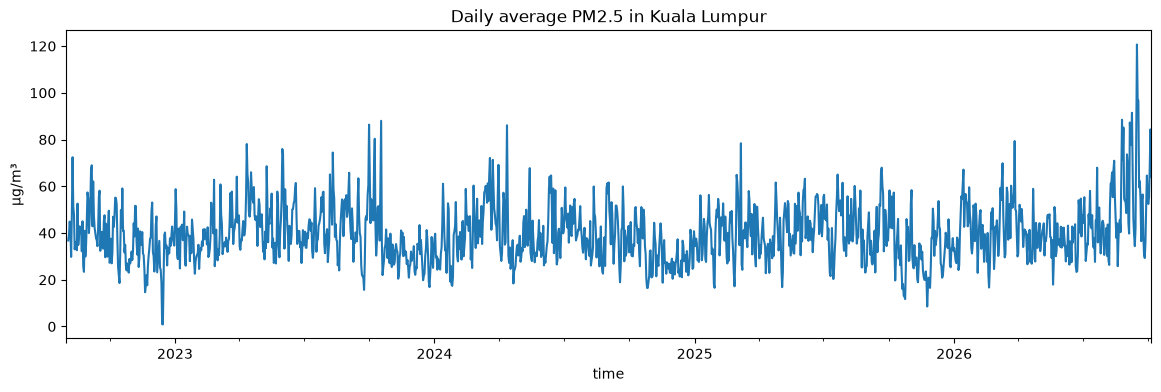

In [8]:
df["pm2_5"].resample("D").mean().plot(figsize=(14, 4), title="Daily average PM2.5 in Kuala Lumpur")
plt.ylabel("µg/m³")
plt.show()

In [10]:
df = df.sort_index()

# Remove the empty block at the start
first_valid = df["pm2_5"].first_valid_index()
df = df.loc[first_valid:]

# Check the hourly grid is complete (no skipped hours)
full = pd.date_range(df.index.min(), df.index.max(), freq="h")
print("Expected hours:", len(full), "| Actual rows:", len(df))
print("Missing PM2.5 now:", df["pm2_5"].isna().sum())

# Save the cleaned data
(root / "data" / "processed").mkdir(parents=True, exist_ok=True)
df.to_parquet(root / "data" / "processed" / "kuala_lumpur_clean.parquet")

Expected hours: 36568 | Actual rows: 36568
Missing PM2.5 now: 0


In [11]:
daily = df["pm2_5"].resample("D").mean()
print("Lowest 5 days:")
print(daily.nsmallest(5).round(1))
print("\nHighest 5 days:")
print(daily.nlargest(5).round(1))

Lowest 5 days:
time
2022-12-15 00:00:00+08:00     0.9
2022-12-14 00:00:00+08:00     1.0
2025-11-24 00:00:00+08:00     8.5
2025-10-24 00:00:00+08:00    11.7
2025-10-23 00:00:00+08:00    12.9
Name: pm2_5, dtype: float64

Highest 5 days:
time
2026-09-15 00:00:00+08:00    120.7
2026-09-17 00:00:00+08:00     96.7
2026-09-16 00:00:00+08:00     96.7
2026-09-08 00:00:00+08:00     91.4
2026-08-25 00:00:00+08:00     88.5
Name: pm2_5, dtype: float64


In [12]:
share = (df["pm2_5"] > 35.4).mean()
print(f"Hours above 35.4 µg/m³: {share:.1%}")

Hours above 35.4 µg/m³: 46.4%


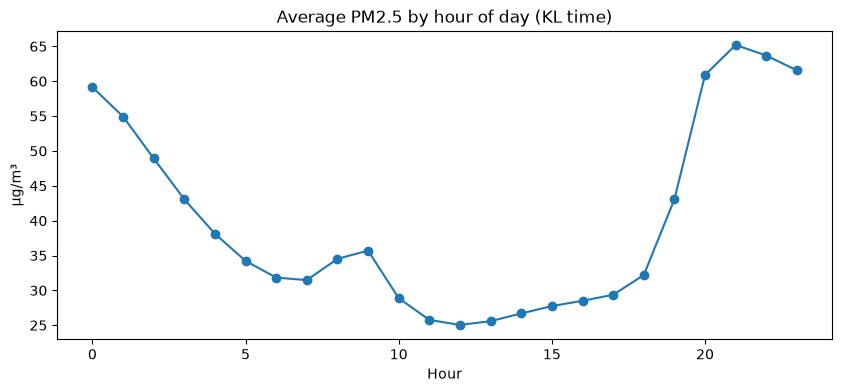

In [13]:
df.groupby(df.index.hour)["pm2_5"].mean().plot(figsize=(10, 4), marker="o",
    title="Average PM2.5 by hour of day (KL time)")
plt.xlabel("Hour")
plt.ylabel("µg/m³")
plt.show()

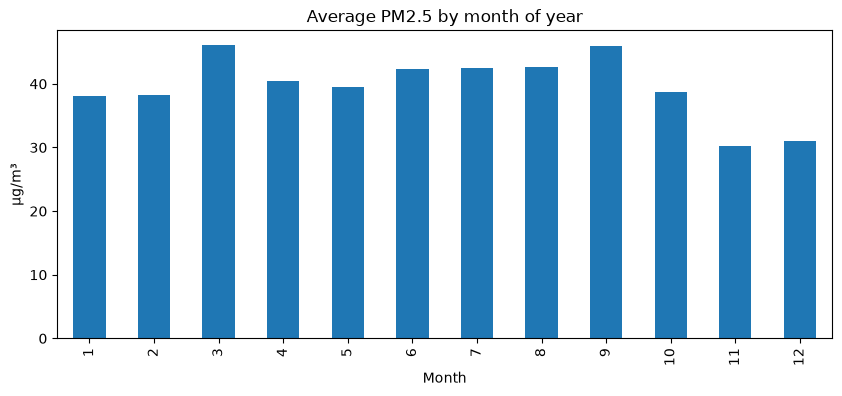

In [14]:
df.groupby(df.index.month)["pm2_5"].mean().plot(kind="bar", figsize=(10, 4),
    title="Average PM2.5 by month of year")
plt.xlabel("Month")
plt.ylabel("µg/m³")
plt.show()

In [15]:
print(df.loc["2022-12-13":"2022-12-16", "pm2_5"].round(1).to_string())

time
2022-12-13 00:00:00+08:00    29.5
2022-12-13 01:00:00+08:00    30.4
2022-12-13 02:00:00+08:00    31.5
2022-12-13 03:00:00+08:00    34.2
2022-12-13 04:00:00+08:00    35.3
2022-12-13 05:00:00+08:00    32.9
2022-12-13 06:00:00+08:00    29.0
2022-12-13 07:00:00+08:00    26.3
2022-12-13 08:00:00+08:00    20.1
2022-12-13 09:00:00+08:00    18.6
2022-12-13 10:00:00+08:00    18.9
2022-12-13 11:00:00+08:00    20.5
2022-12-13 12:00:00+08:00    21.9
2022-12-13 13:00:00+08:00    17.0
2022-12-13 14:00:00+08:00    13.3
2022-12-13 15:00:00+08:00    12.6
2022-12-13 16:00:00+08:00    11.1
2022-12-13 17:00:00+08:00    11.0
2022-12-13 18:00:00+08:00    13.1
2022-12-13 19:00:00+08:00    15.3
2022-12-13 20:00:00+08:00     1.2
2022-12-13 21:00:00+08:00     1.2
2022-12-13 22:00:00+08:00     1.2
2022-12-13 23:00:00+08:00     1.2
2022-12-14 00:00:00+08:00     1.2
2022-12-14 01:00:00+08:00     1.2
2022-12-14 02:00:00+08:00     1.2
2022-12-14 03:00:00+08:00     1.2
2022-12-14 04:00:00+08:00     1.2
2022-12-1

In [16]:
print(df.loc["2022-12-13":"2022-12-16", "pm2_5"].round(1).to_string())

time
2022-12-13 00:00:00+08:00    29.5
2022-12-13 01:00:00+08:00    30.4
2022-12-13 02:00:00+08:00    31.5
2022-12-13 03:00:00+08:00    34.2
2022-12-13 04:00:00+08:00    35.3
2022-12-13 05:00:00+08:00    32.9
2022-12-13 06:00:00+08:00    29.0
2022-12-13 07:00:00+08:00    26.3
2022-12-13 08:00:00+08:00    20.1
2022-12-13 09:00:00+08:00    18.6
2022-12-13 10:00:00+08:00    18.9
2022-12-13 11:00:00+08:00    20.5
2022-12-13 12:00:00+08:00    21.9
2022-12-13 13:00:00+08:00    17.0
2022-12-13 14:00:00+08:00    13.3
2022-12-13 15:00:00+08:00    12.6
2022-12-13 16:00:00+08:00    11.1
2022-12-13 17:00:00+08:00    11.0
2022-12-13 18:00:00+08:00    13.1
2022-12-13 19:00:00+08:00    15.3
2022-12-13 20:00:00+08:00     1.2
2022-12-13 21:00:00+08:00     1.2
2022-12-13 22:00:00+08:00     1.2
2022-12-13 23:00:00+08:00     1.2
2022-12-14 00:00:00+08:00     1.2
2022-12-14 01:00:00+08:00     1.2
2022-12-14 02:00:00+08:00     1.2
2022-12-14 03:00:00+08:00     1.2
2022-12-14 04:00:00+08:00     1.2
2022-12-1

In [17]:
df.groupby(df.index.month)["precipitation"].mean().round(2)

time
1     0.34
2     0.27
3     0.25
4     0.43
5     0.38
6     0.29
7     0.19
8     0.34
9     0.33
10    0.36
11    0.51
12    0.56
Name: precipitation, dtype: float64

In [18]:
glitch = df.loc["2022-12-14":"2022-12-15"].index
df["pm2_5_filled"] = 0                      # 1 marks hours we repaired
df.loc[glitch, "pm2_5_filled"] = 1
df.loc[glitch, ["pm2_5", "pm10", "nitrogen_dioxide", "ozone",
                "sulphur_dioxide", "carbon_monoxide"]] = float("nan")
df = df.interpolate(limit=60, limit_area="inside")
print("Missing PM2.5:", df["pm2_5"].isna().sum())
df.to_parquet(root / "data" / "processed" / "kuala_lumpur_clean.parquet")

Missing PM2.5: 0


In [19]:
print(df.loc["2022-12-13":"2022-12-16", "pm2_5"].round(1).to_string())


time
2022-12-13 00:00:00+08:00    29.5
2022-12-13 01:00:00+08:00    30.4
2022-12-13 02:00:00+08:00    31.5
2022-12-13 03:00:00+08:00    34.2
2022-12-13 04:00:00+08:00    35.3
2022-12-13 05:00:00+08:00    32.9
2022-12-13 06:00:00+08:00    29.0
2022-12-13 07:00:00+08:00    26.3
2022-12-13 08:00:00+08:00    20.1
2022-12-13 09:00:00+08:00    18.6
2022-12-13 10:00:00+08:00    18.9
2022-12-13 11:00:00+08:00    20.5
2022-12-13 12:00:00+08:00    21.9
2022-12-13 13:00:00+08:00    17.0
2022-12-13 14:00:00+08:00    13.3
2022-12-13 15:00:00+08:00    12.6
2022-12-13 16:00:00+08:00    11.1
2022-12-13 17:00:00+08:00    11.0
2022-12-13 18:00:00+08:00    13.1
2022-12-13 19:00:00+08:00    15.3
2022-12-13 20:00:00+08:00     1.2
2022-12-13 21:00:00+08:00     1.2
2022-12-13 22:00:00+08:00     1.2
2022-12-13 23:00:00+08:00     1.2
2022-12-14 00:00:00+08:00     1.2
2022-12-14 01:00:00+08:00     1.2
2022-12-14 02:00:00+08:00     1.2
2022-12-14 03:00:00+08:00     1.2
2022-12-14 04:00:00+08:00     1.2
2022-12-1

In [20]:
df.groupby(df.index.month)["precipitation"].mean().round(2)

time
1     0.34
2     0.27
3     0.25
4     0.43
5     0.38
6     0.29
7     0.19
8     0.34
9     0.33
10    0.36
11    0.51
12    0.56
Name: precipitation, dtype: float64

In [21]:
bad = df.loc["2022-12-13 20:00":"2022-12-16 07:00"].index
print("Bad hours:", len(bad))

aq_cols = ["pm2_5", "pm10", "nitrogen_dioxide", "ozone",
           "sulphur_dioxide", "carbon_monoxide"]
df["is_glitch"] = 0
df.loc[bad, "is_glitch"] = 1
df.loc[bad, aq_cols] = float("nan")

print("Missing PM2.5 now:", df["pm2_5"].isna().sum())
df.to_parquet(root / "data" / "processed" / "kuala_lumpur_clean.parquet")

Bad hours: 60
Missing PM2.5 now: 60


In [22]:
stuck = (df["pm2_5"].diff() == 0).astype(int)
runs = stuck.groupby((stuck == 0).cumsum()).sum()
print("Longest identical-value run (hours):", runs.max())


Longest identical-value run (hours): 2
